    Annual Spending  Visits per Month
0             10000                 2
1             12000                 3
2             15000                 2
3             18000                 4
4             20000                 3
5             50000                 8
6             55000                 9
7             60000                 7
8             65000                10
9             70000                 8
10            90000                15
11            95000                14
12           100000                16
13           110000                18
14           120000                17

Cluster Results:
    Annual Spending  Visits per Month  Cluster
0             10000                 2        2
1             12000                 3        2
2             15000                 2        2
3             18000                 4        2
4             20000                 3        2
5             50000                 8        0
6             55000                 9        

C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


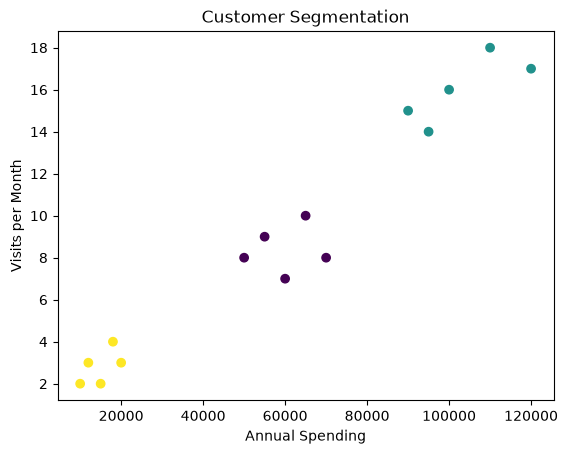


Average Spending:
Cluster
0     60000.0
1    103000.0
2     15000.0
Name: Annual Spending, dtype: float64
K = 2
Inertia: 7.57729094764698
Silhouette Score: 0.6270415954030362
K = 3
Inertia: 1.255708935966977
Silhouette Score: 0.7496152911398504


C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K = 4
Inertia: 0.6541456684691107
Silhouette Score: 0.6960378769090809

DBSCAN Results:
    Annual Spending  Visits per Month  Cluster  DBSCAN Cluster
0             10000                 2        2               0
1             12000                 3        2               0
2             15000                 2        2               0
3             18000                 4        2               0
4             20000                 3        2               0
5             50000                 8        0               1
6             55000                 9        0               1
7             60000                 7        0               1
8             65000                10        0               1
9             70000                 8        0               1
10            90000                15        1               2
11            95000                14        1               2
12           100000                16        1               2
13           110000           

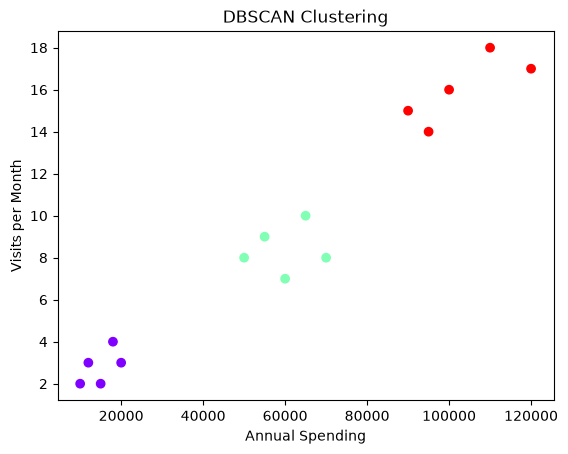

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# 1. Create Dataset
data = {
    "Annual Spending": [10000,12000,15000,18000,20000,
                        50000,55000,60000,65000,70000,
                        90000,95000,100000,110000,120000],
    "Visits per Month": [2,3,2,4,3,8,9,7,10,8,15,14,16,18,17]
}

df = pd.DataFrame(data)
print(df)

# 2. Feature Scaling and K-Means
scaler = StandardScaler()
X = scaler.fit_transform(df)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X)

print("\nCluster Results:")
print(df)

# 3. Visualize Clusters
plt.scatter(df["Annual Spending"], df["Visits per Month"],
            c=df["Cluster"], cmap="viridis")
plt.xlabel("Annual Spending")
plt.ylabel("Visits per Month")
plt.title("Customer Segmentation")
plt.show()

print("\nAverage Spending:")
print(df.groupby("Cluster")["Annual Spending"].mean())

# 4. Compare K=2, K=3 and K=4
inertia = []

for k in range(2,5):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    inertia.append(model.inertia_)

    print("K =", k)
    print("Inertia:", model.inertia_)
    print("Silhouette Score:", silhouette_score(X, labels))


# 5. DBSCAN
dbscan = DBSCAN(eps=0.8, min_samples=2)
df["DBSCAN Cluster"] = dbscan.fit_predict(X)

print("\nDBSCAN Results:")
print(df)

plt.scatter(df["Annual Spending"], df["Visits per Month"],
            c=df["DBSCAN Cluster"], cmap="rainbow")
plt.xlabel("Annual Spending")
plt.ylabel("Visits per Month")
plt.title("DBSCAN Clustering")
plt.show()
